In [27]:
import numpy as np
import matplotlib.pyplot as plt
import sunpy 
import sunpy.map
from scipy.io import readsav
from glob import glob 
from astropy.io import fits
from tqdm.notebook import tqdm
import os 
import sys 
sys.path.insert(0, "/cluster/home/zhuyin/scripts/EMToolKitPlus/")

from varying_tresp_dem import varying_tresp_dem
from spatial_reg_dem import spatial_reg_dem


In [14]:
aia_response = readsav("../../sav/aia_response_2022_10_24.sav")

In [15]:
logte = aia_response["interp_logte"]
resp_euv = aia_response["resp_euv"]

In [16]:
resp_euv.shape

(26, 6)

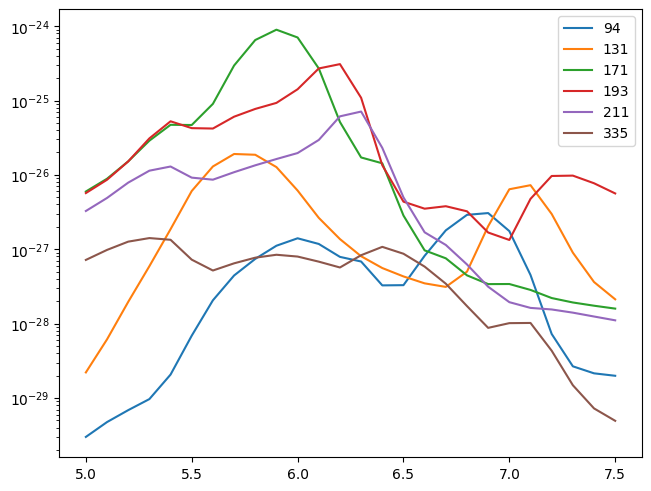

In [17]:
channels = ["94", "131", "171", "193", "211", "335"]
fig, ax = plt.subplots(layout='constrained')
for ii in range(6):
    ax.plot(logte, resp_euv[:, ii], label=channels[ii])
ax.set_yscale("log")
ax.legend()

In [18]:
aia_94_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/94/*.94.image.fits"))
aia_131_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/131/*.131.image.fits"))
aia_171_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/171/*.171.image.fits"))
aia_193_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/193/*.193.image.fits"))
aia_211_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/211/*.211.image.fits"))
aia_335_files = sorted(glob("../../data/pid_1_123_aux/AIA/DEM_seq/raw/335/*.335.image.fits"))

In [19]:
print(len(aia_94_files), len(aia_131_files), len(aia_171_files), len(aia_193_files), len(aia_211_files), len(aia_335_files))

200 200 200 200 200 200


In [13]:
def estimate_aia_error(aia_array):
    refchannels = np.array(['AIA94_THIN', 'AIA131_THIN', 'AIA171_THIN', 
        'AIA193_THIN', 'AIA211_THIN', 'AIA335_THIN'])
    refg = np.array([2.128, 1.523, 1.168, 1.024, 0.946, 0.596])
    refn = np.array([1.14, 1.18, 1.15, 1.2, 1.2, 1.18])

    return np.sqrt(np.clip(aia_array * refg[np.newaxis, np.newaxis, :], 0.0, None) + \
                   refn[np.newaxis, np.newaxis, :] ** 2)

In [29]:
aia_array = np.zeros((100, 100, 6, len(aia_94_files)))
aia_error = np.zeros((100, 100, 6, len(aia_94_files)))
aia_exptimes = np.zeros((6, len(aia_94_files)))

for ii in tqdm(range(len(aia_94_files))):
    aia_array[:,:,0,ii] = fits.getdata(aia_94_files[ii], ext=1)
    aia_exptimes[0,ii] = fits.getheader(aia_94_files[ii], ext=1)["EXPTIME"]
    aia_array[:,:,1,ii] = fits.getdata(aia_131_files[ii], ext=1)
    aia_exptimes[1,ii] = fits.getheader(aia_131_files[ii], ext=1)["EXPTIME"]
    aia_array[:,:,2,ii] = fits.getdata(aia_171_files[ii], ext=1)
    aia_exptimes[2,ii] = fits.getheader(aia_171_files[ii], ext=1)["EXPTIME"]
    aia_array[:,:,3,ii] = fits.getdata(aia_193_files[ii], ext=1)
    aia_exptimes[3,ii] = fits.getheader(aia_193_files[ii], ext=1)["EXPTIME"]
    aia_array[:,:,4,ii] = fits.getdata(aia_211_files[ii], ext=1)
    aia_exptimes[4,ii] = fits.getheader(aia_211_files[ii], ext=1)["EXPTIME"]
    aia_array[:,:,5,ii] = fits.getdata(aia_335_files[ii], ext=1)
    aia_exptimes[5,ii] = fits.getheader(aia_335_files[ii], ext=1)["EXPTIME"]

    aia_error[:,:,:,ii] = estimate_aia_error(aia_array[:,:,:,ii])


  0%|          | 0/200 [00:00<?, ?it/s]

In [56]:
def single_aia_dem(
    aia_array_single,
    aia_error_single,
    aia_exptimes_single,
    logte,
    resp_euv,
    method="pixel",
    **kwargs 
):
    
    if method == "pixel":
        dems, chi2, info = varying_tresp_dem(
            aia_array_single,
            aia_error_single,
            aia_exptimes_single,
            logte,
            resp_euv,
            backend="numba"
        )
    
    elif method == "reg":

        spatial_con = kwargs.pop("spatial_con", 0.3)
        chi2_target = kwargs.pop("chi2_target", 1.0)

        dems, chi2, info = spatial_reg_dem(
            aia_array_single,
            aia_error_single,
            aia_exptimes_single,
            logte,
            resp_euv,
            spatial_con=spatial_con,
            chi2_target=chi2_target,
            backend="numba",
            **kwargs
        )
        
    return dems, chi2, info
    

In [46]:
dems_test, chi2_test, info_test = single_aia_dem(
    aia_array[:, :, :, 0],
    aia_error[:, :, :, 0],
    aia_exptimes[:, 0],
    logte,
    resp_euv
)

In [32]:
dems_test.shape

(100, 100, 26)

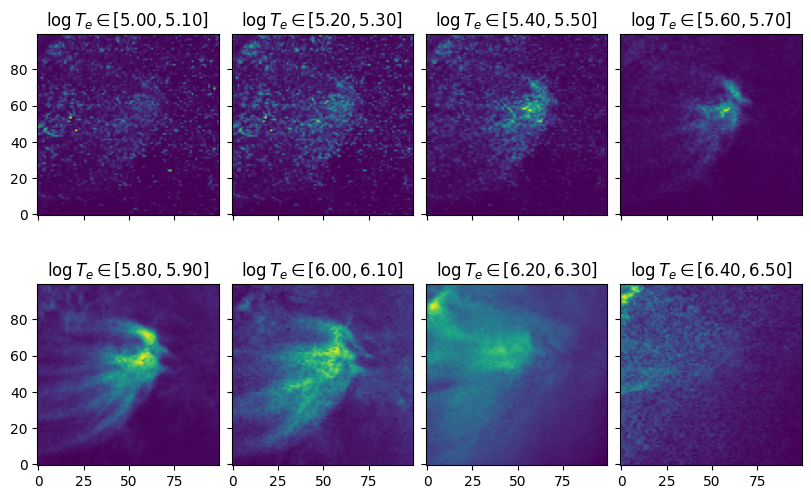

In [48]:
fig, axes = plt.subplots(2, 4, figsize=(8, 5), layout='constrained', sharex=True, sharey=True)
axes = axes.flatten()

for ii in range(8):
    dem_test_avg_ = np.nansum(dems_test[:,:,ii*2:ii*2+2], axis=2)
    axes[ii].imshow(dem_test_avg_, origin="lower", aspect=1)
    axes[ii].set_title(rf"$\log T_e \in [{logte[ii*2]:.2f}, {logte[ii*2+1]:.2f}]$")

In [60]:
dems_test_reg, chi2_test_reg, info_test_reg = single_aia_dem(
    aia_array[:, :, :, 0],
    aia_error[:, :, :, 0],
    aia_exptimes[:, 0],
    logte,
    resp_euv,
    method="reg",
    spatial_con=5.0,
    init_smooth=0
)

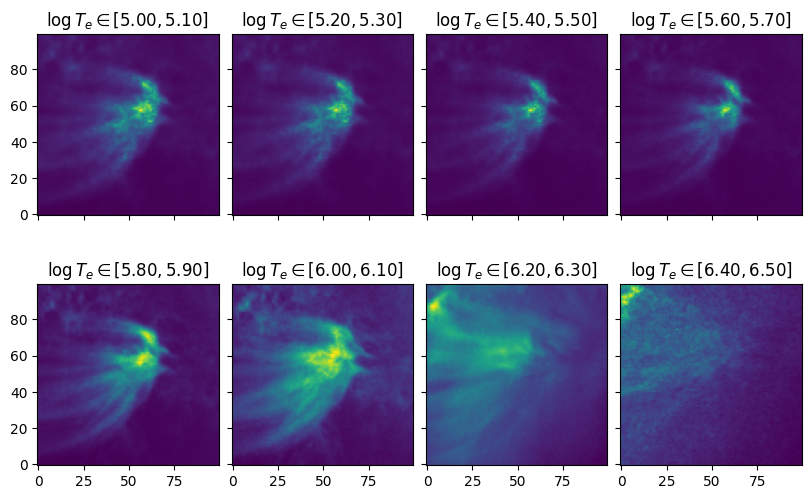

In [61]:
fig, axes = plt.subplots(2, 4, figsize=(8, 5), layout='constrained', sharex=True, sharey=True)
axes = axes.flatten()

for ii in range(8):
    dem_test_avg_ = np.nansum(dems_test_reg[:,:,ii*2:ii*2+2], axis=2)
    axes[ii].imshow(dem_test_avg_, origin="lower", aspect=1)
    axes[ii].set_title(rf"$\log T_e \in [{logte[ii*2]:.2f}, {logte[ii*2+1]:.2f}]$")

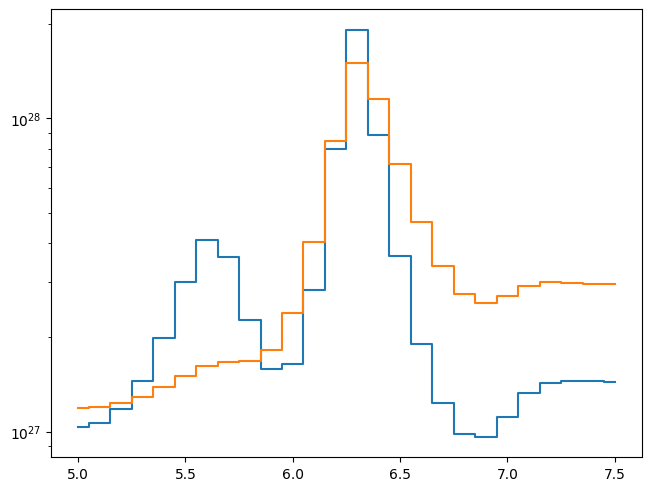

In [64]:
select_x, select_y = 40, 50

fig, ax = plt.subplots(layout='constrained')

ax.step(logte, dems_test[select_y, select_x, :], where="mid", label="pixel-wise")
ax.step(logte, dems_test_reg[select_y, select_x, :], where="mid", label="spatial-reg")
ax.set_yscale("log")